# Supervised Classification Modeling & Hyperparameter Tuning

This notebook trains and compares four classification models, tunes their hyperparameters with `GridSearchCV` and stratified 5-fold cross-validation, evaluates validation performance, plots ROC curves and confusion matrices, selects a champion model, and saves it as `champion_model.joblib`.

**Dataset:** Scikit-learn's built-in Breast Cancer Wisconsin dataset. It is a public, bundled educational dataset, not personal data.  
**Task:** Binary classification.  
**Important:** This is an educational portfolio project, not a medical diagnostic system.

## 1. Imports and reproducibility

Install dependencies from `requirements.txt` if needed. This notebook uses only Scikit-learn models, so XGBoost/LightGBM are not required.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier
from sklearn.base import clone
import joblib

RANDOM_STATE = 42

## 2. Load and inspect the dataset

The dataset has numeric features and a binary target. In this dataset, target 0 is malignant and target 1 is benign. We will keep this educational context in mind when interpreting metrics.

In [2]:
dataset = load_breast_cancer(as_frame=True)
X = dataset.data
y = dataset.target

print("Feature matrix shape:", X.shape)
print("Target distribution:")
print(y.map({0: "malignant", 1: "benign"}).value_counts())
display(X.head())

Feature matrix shape: (569, 30)
Target distribution:
target
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 3. Create a stratified train/validation split

The holdout validation set is not used during cross-validation hyperparameter tuning.

In [3]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train))
print("Validation rows:", len(X_valid))

Training rows: 455
Validation rows: 114


## 4. Define four distinct model architectures and tuning grids

All preprocessing is placed inside a Scikit-learn Pipeline to help prevent data leakage. Scaling is used for Logistic Regression; tree-based models do not require scaling, so their pipelines pass features through unchanged.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models_and_grids = {
    "Logistic Regression": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
        ]),
        {
            "model__C": [0.1, 1.0, 10.0],
            "model__class_weight": [None, "balanced"]
        }
    ),
    "Random Forest": (
        Pipeline([
            ("model", RandomForestClassifier(random_state=RANDOM_STATE))
        ]),
        {
            "model__n_estimators": [100, 200],
            "model__max_depth": [None, 8],
            "model__min_samples_leaf": [1, 2]
        }
    ),
    "Gradient Boosting": (
        Pipeline([
            ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))
        ]),
        {
            "model__n_estimators": [100, 150],
            "model__learning_rate": [0.05, 0.1],
            "model__max_depth": [2, 3]
        }
    ),
    "Extra Trees": (
        Pipeline([
            ("model", ExtraTreesClassifier(random_state=RANDOM_STATE))
        ]),
        {
            "model__n_estimators": [100, 200],
            "model__max_depth": [None, 8],
            "model__min_samples_leaf": [1, 2]
        }
    )
}

## 5. Hyperparameter optimization with GridSearchCV

We use ROC-AUC as the cross-validation scoring metric and stratified 5-fold cross-validation. Grid search may take a little time depending on your computer.

In [5]:
searches = {}
comparison_rows = []

for model_name, (pipeline, param_grid) in models_and_grids.items():
    print(f"Training and tuning: {model_name}")
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )
    search.fit(X_train, y_train)
    searches[model_name] = search

    valid_pred = search.predict(X_valid)
    valid_proba = search.predict_proba(X_valid)[:, 1]

    comparison_rows.append({
        "Model": model_name,
        "Best CV ROC-AUC": search.best_score_,
        "Validation Accuracy": accuracy_score(y_valid, valid_pred),
        "Validation Precision": precision_score(y_valid, valid_pred, zero_division=0),
        "Validation Recall": recall_score(y_valid, valid_pred, zero_division=0),
        "Validation F1": f1_score(y_valid, valid_pred, zero_division=0),
        "Validation ROC-AUC": roc_auc_score(y_valid, valid_proba),
        "Best Parameters": search.best_params_
    })

comparison = pd.DataFrame(comparison_rows).sort_values(
    by="Validation ROC-AUC", ascending=False
).reset_index(drop=True)

display(comparison.drop(columns=["Best Parameters"]).round(4))

Training and tuning: Logistic Regression


Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Training and tuning: Random Forest


Training and tuning: Gradient Boosting


Training and tuning: Extra Trees


,Model,Best CV ROC-AUC,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Validation ROC-AUC
0,Logistic Regression,0.9959,0.9825,0.9861,0.9861,0.9861,0.9954
1,Random Forest,0.9901,0.9561,0.9589,0.9722,0.9655,0.9950
2,Extra Trees,0.9943,0.9561,0.9589,0.9722,0.9655,0.9927
3,Gradient Boosting,0.9929,0.9474,0.9459,0.9722,0.9589,0.9911


## 6. Select the champion model

The champion is selected using the highest holdout validation ROC-AUC. For real projects, also consider the cost of false positives/false negatives, business requirements, fairness, calibration, and deployment constraints.

In [6]:
champion_name = comparison.loc[0, "Model"]
champion_search = searches[champion_name]
champion_model = champion_search.best_estimator_

print("Champion model:", champion_name)
print("Best cross-validation ROC-AUC:", round(champion_search.best_score_, 4))
print("Validation ROC-AUC:", round(roc_auc_score(y_valid, champion_model.predict_proba(X_valid)[:, 1]), 4))
print("Best parameters:", champion_search.best_params_)

print("\nClassification report:")
print(classification_report(
    y_valid, champion_model.predict(X_valid),
    target_names=dataset.target_names,
    zero_division=0
))

Champion model: Logistic Regression
Best cross-validation ROC-AUC: 0.9959
Validation ROC-AUC: 0.9954
Best parameters: {'model__C': 1.0, 'model__class_weight': None}

Classification report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



## 7. Plot ROC-AUC curves for all tuned models

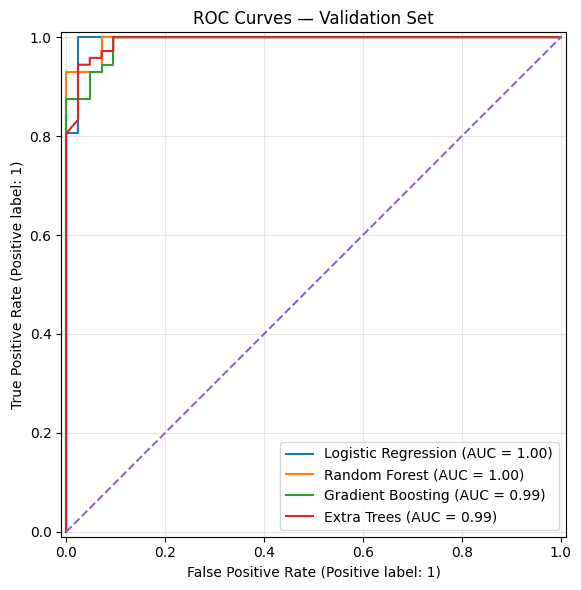

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
for model_name, search in searches.items():
    RocCurveDisplay.from_estimator(
        search.best_estimator_, X_valid, y_valid, ax=ax, name=model_name
    )
ax.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
ax.set_title("ROC Curves — Validation Set")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Champion model confusion matrix

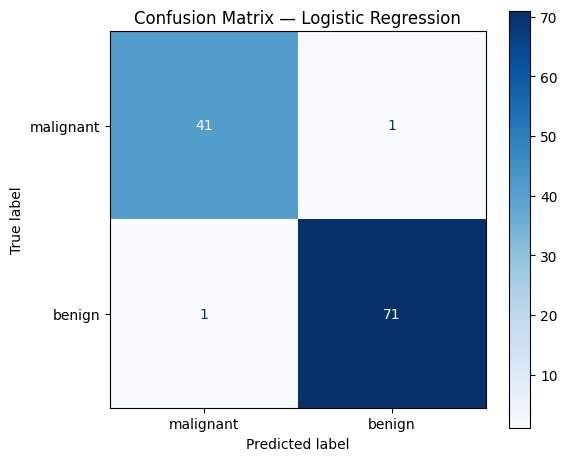

In [8]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(
    champion_model, X_valid, y_valid,
    display_labels=dataset.target_names,
    cmap="Blues", ax=ax
)
ax.set_title(f"Confusion Matrix — {champion_name}")
plt.tight_layout()
plt.show()

## 9. Save the trained champion model

The file is saved to the current notebook directory. Keep the model and its Scikit-learn version compatible when loading it later.

In [9]:
MODEL_PATH = "champion_model.joblib"
joblib.dump(champion_model, MODEL_PATH)
print(f"Saved champion model to: {MODEL_PATH}")

# Verify the serialized model can be loaded and make predictions
loaded_model = joblib.load(MODEL_PATH)
sample_predictions = loaded_model.predict(X_valid.iloc[:5])
print("First five validation predictions:", sample_predictions.tolist())

Saved champion model to: champion_model.joblib
First five validation predictions: [0, 1, 0, 1, 0]


## 10. Save the model comparison table

This creates a CSV report that can be committed to GitHub along with the notebook.

In [10]:
comparison.drop(columns=["Best Parameters"]).to_csv(
    "model_comparison.csv", index=False
)
print("Saved model_comparison.csv")

Saved model_comparison.csv


## Conclusion

- Four distinct model architectures were trained and tuned.
- Hyperparameters were optimized with GridSearchCV and stratified 5-fold cross-validation.
- Validation Precision, Recall, F1, ROC-AUC, Accuracy, ROC curves, and a confusion matrix were evaluated.
- The champion was selected using validation ROC-AUC.
- The trained champion model was serialized to `champion_model.joblib`.

**Limitations:** This is an educational demonstration using a bundled dataset. Do not use this model for clinical decisions or real-world diagnosis. Re-evaluate with appropriate domain validation before any practical use.